# Face Detection with OpenCV (VS Code / local Jupyter)

This notebook runs face detection step by step on your machine, then checks the deployment files and launches the Streamlit app (`face_streamlit.py`) that sits in the same folder.

**Local requirements:** `pip install opencv-python numpy pillow matplotlib streamlit`

> The notebook is for local experimenting only. It is **not** needed for online deployment; upload only `face_streamlit.py`, `haarcascade_frontalface_default.xml` and `requirements.txt` to GitHub.
>
> Locally you need `opencv-python` (the webcam cell uses `cv2.imshow`). The deployed `requirements.txt` uses `opencv-python-headless` instead, because Streamlit Cloud has no display libraries.


## 1. Setup

In [1]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))
print("Haar cascade path:", cv2.data.haarcascades)

OpenCV version: 4.10.0
CascadeClassifier: True
Haar cascade path: c:\Users\satya\AppData\Local\Programs\Python\Python311\Lib\site-packages\cv2\data\


In [ ]:
import cv2
import numpy as np

# Haar cascade ships with opencv-python - no manual download needed
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Set this to the path of your image (a raw string r"..." works for Windows paths)
IMAGE_PATH = r"your_image.jpg"


## 2. Load and view the image
A window will pop up; press any key to close it (same behavior as your original script).

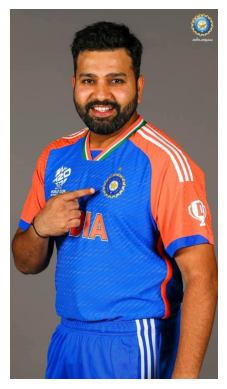

In [3]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError(f"Could not load image at {IMAGE_PATH}")

# OpenCV reads images as BGR
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.axis("off")
plt.show()

## 3. Convert to grayscale

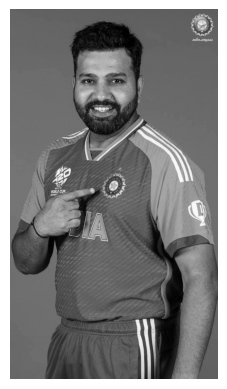

In [4]:
import cv2
import matplotlib.pyplot as plt

# Convert BGR image to grayscale
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Display grayscale image
plt.imshow(gray_img, cmap="gray")
plt.axis("off")
plt.show()

## 4. Detect faces in the static image

Faces detected: 1


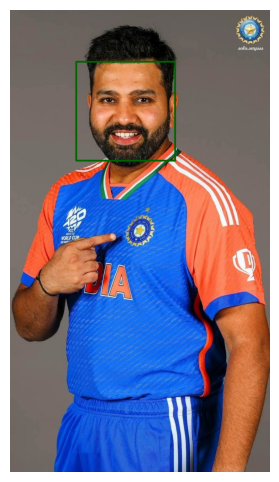

In [5]:
import matplotlib.pyplot as plt

faces = face_cascade.detectMultiScale(
    gray_img,
    scaleFactor=1.1,
    minNeighbors=5
)

img_with_faces = img.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        img_with_faces,
        (x, y),
        (x + w, y + h),
        (0, 100, 0),  # dark green (BGR)
         3
    )

print(f"Faces detected: {len(faces)}")

# Convert BGR → RGB for Jupyter/Matplotlib
img_rgb = cv2.cvtColor(img_with_faces, cv2.COLOR_BGR2RGB)

# Display inside notebook
plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

## 5. Live webcam detection — rectangle
Opens your webcam in a live window. Press **q** to close it.

In [6]:
import cv2

# Load Haar cascade ONCE
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Open webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Could not open webcam")
else:
    window_name = "Webcam - Face Detection"

    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)

    # Bring window to foreground
    cv2.setWindowProperty(
        window_name,
        cv2.WND_PROP_TOPMOST,
        1
    )

    cv2.setWindowProperty(
        window_name,
        cv2.WND_PROP_TOPMOST,
        0
    )

    while True:
        ret, frame = cap.read()

        if not ret:
            print("Could not read frame")
            break

        # Convert to grayscale
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Detect faces
        faces = face_cascade.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5
        )

        # Draw rectangle
        for (x, y, w, h) in faces:
            cv2.rectangle(
                frame,
                (x, y),
                (x + w, y + h),
                (0, 100, 0),  # dark green (BGR)
                 3
            )

        # Show webcam
        cv2.imshow(window_name, frame)

        # Press Q to quit
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    cap.release()
    cv2.destroyAllWindows()

## 6. Save the Haar cascade for deployment

Face detection does not have a trained neural-network model. It uses OpenCV's pre-trained Haar cascade. This cell copies the cascade XML into the project folder so the deployment code can use a local file.


In [7]:
import shutil
import os

CASCADE_SOURCE = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
CASCADE_DEST = "haarcascade_frontalface_default.xml"

shutil.copy2(CASCADE_SOURCE, CASCADE_DEST)

print("Cascade saved to:", os.path.abspath(CASCADE_DEST))


Cascade saved to: c:\Users\satya\Downloads\john_project\haarcascade_frontalface_default.xml


## 7. Check the deployment files

These must be in **the same folder as this notebook**:

```text
Face_Detection_Deployment.ipynb       <- this notebook (local use only)
haarcascade_frontalface_default.xml   <- created by section 6
face_streamlit.py                     <- Streamlit web app
requirements.txt                      <- deployment dependencies (do not overwrite)
```

Section 6 saves the cascade XML, and `face_streamlit.py` loads it from the same folder.


In [ ]:
import os, sys, subprocess, time

PROJECT_DIR = os.getcwd()          # VS Code uses the notebook's folder by default
print("Project folder:", PROJECT_DIR)

# Check every file is in place.
# requirements.txt is NOT rewritten here: the deployment version must use
# opencv-python-headless, while this notebook needs opencv-python locally.
required_files = [
    "haarcascade_frontalface_default.xml",
    "face_streamlit.py",
    "requirements.txt",
]
all_ok = True
for name in required_files:
    exists = os.path.exists(os.path.join(PROJECT_DIR, name))
    all_ok &= exists
    print(("OK       " if exists else "MISSING  ") + name)

if not all_ok:
    raise FileNotFoundError("Put the missing files in the same folder as this notebook "
                            "(and run section 6 to create the cascade XML).")
print("\nAll files present.")


## 8. Run the Streamlit app

This launches `face_streamlit.py` and opens it in your browser at **http://localhost:8501**. The app runs in the background, so you can keep using the notebook. Run the next cell when you want to stop it.


In [ ]:
import webbrowser

streamlit_proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "face_streamlit.py",
     "--server.port", "8501", "--server.headless", "true"],
    cwd=PROJECT_DIR,
)

time.sleep(5)
webbrowser.open("http://localhost:8501")
print("Streamlit running at http://localhost:8501")

Streamlit running at http://localhost:8501


In [ ]:
# Run this cell to stop the Streamlit app
if "streamlit_proc" in globals() and streamlit_proc.poll() is None:
    streamlit_proc.terminate()
    streamlit_proc.wait()
    print("Streamlit stopped.")
else:
    print("Streamlit is not running.")

Streamlit stopped.


## 9. Running the app without the notebook

Once everything works, run it from a terminal in this folder:

```bash
pip install -r requirements.txt
streamlit run face_streamlit.py     # -> http://localhost:8501
```

To deploy online, push `face_streamlit.py`, `haarcascade_frontalface_default.xml` and `requirements.txt` to GitHub and create the app on https://share.streamlit.io.
